In [1]:
import numpy as np

import matplotlib.pyplot as plt
np.random.seed(42)

arms = ["Video Lectures", "Interactive Quizzes", "Gamified Modules"]

probabilities = [0.6, 0.4, 0.7]

n_arms = len(arms)

rounds = 1000
counts_ucb = np.zeros(n_arms)

values_ucb = np.zeros(n_arms)

rewards_ucb = []

cumulative_rewards_ucb = []

total_reward = 0

for t in range(rounds):

    if t < n_arms:
        action = t
    else:

        confidence = np.sqrt(
            (2 * np.log(t + 1)) / counts_ucb
        )

        ucb = values_ucb + confidence

        action = np.argmax(ucb)

    reward = np.random.binomial(1, probabilities[action])

    counts_ucb[action] += 1

    values_ucb[action] += (
        reward - values_ucb[action]
    ) / counts_ucb[action]

    total_reward += reward

    rewards_ucb.append(reward)

    cumulative_rewards_ucb.append(total_reward)

print("========== UCB ==========")

for i in range(n_arms):
    print(arms[i], "selected", int(counts_ucb[i]), "times")

print("Total Reward =", total_reward)

========== UCB ==========
Video Lectures selected 257 times
Interactive Quizzes selected 68 times
Gamified Modules selected 675 times
Total Reward = 664


In [2]:
alpha = np.ones(n_arms)

beta = np.ones(n_arms)

counts_ts = np.zeros(n_arms)

rewards_ts = []

cumulative_rewards_ts = []

total_reward = 0

for t in range(rounds):

    samples = np.random.beta(alpha, beta)

    action = np.argmax(samples)

    reward = np.random.binomial(1, probabilities[action])

    counts_ts[action] += 1

    if reward == 1:

        alpha[action] += 1
    else:

        beta[action] += 1

    total_reward += reward

    rewards_ts.append(reward)

    cumulative_rewards_ts.append(total_reward)


print("\n========== Thompson Sampling ==========")


for i in range(n_arms):
    print(arms[i], "selected", int(counts_ts[i]), "times")


print("Total Reward =", total_reward)


========== Thompson Sampling ==========
Video Lectures selected 279 times
Interactive Quizzes selected 15 times
Gamified Modules selected 706 times
Total Reward = 671


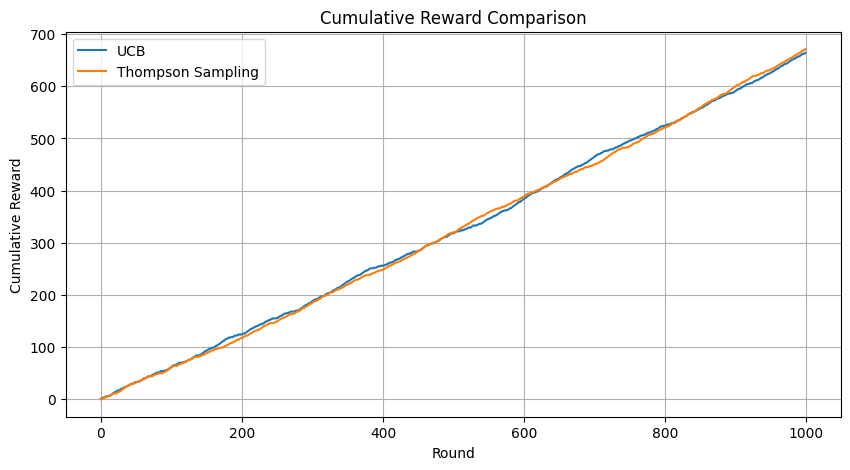

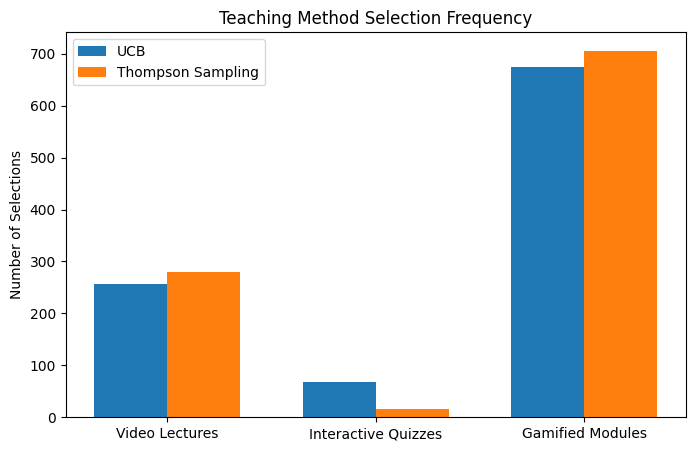

In [5]:
plt.figure(figsize=(10,5))

plt.plot(cumulative_rewards_ucb, label="UCB")

plt.plot(cumulative_rewards_ts, label="Thompson Sampling")

plt.xlabel("Round")

plt.ylabel("Cumulative Reward")

plt.title("Cumulative Reward Comparison")

plt.legend()

plt.grid()

plt.show()

x = np.arange(n_arms)

width = 0.35

plt.figure(figsize=(8,5))

plt.bar(x-width/2,
        counts_ucb,
        width,
        label="UCB")

plt.bar(x+width/2,
        counts_ts,
        width,
        label="Thompson Sampling")

plt.xticks(x, arms)

plt.ylabel("Number of Selections")

plt.title("Teaching Method Selection Frequency")
plt.legend()
plt.show()